<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/02_descriptive_charts_sahil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Descriptive charts: design attributes by decade

Compares the design attributes of games across decades of publication: play time, player-count range, minimum age, number of listed mechanics, and the mix of mechanics and categories. Each chart shows the spread within a decade, not just an average, and the number of games behind it.

Data: `data/bgg_clean.csv` from the cleaning notebook. Scope: games published in the 1970s through the 2020s with a known year. The 2020s covers 2020 to the January 2022 snapshot only. Games with a missing value for the attribute being plotted are left out of that chart, and the count used is shown.

In [1]:
# --- Sahil Dalal: descriptive charts, design attributes by decade ---
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13. Every code cell in this notebook was generated with Claude Code and reviewed, run and edited by Sahil Dalal.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load and scope

In [2]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Load the cleaned catalogue straight from the repository; the same line works in Colab and locally.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

(21631, 24)


In [3]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Keep games published 1970 or later and label each by decade.
dec = games[games["decade"] >= 1970].copy()
dec["decade"] = dec["decade"].astype(int).astype(str) + "s"
print("games 1970s to 2020s:", len(dec), "| earlier with a known year:", (games["decade"] < 1970).sum(), "| year unknown:", games["decade"].isna().sum())
counts = dec["decade"].value_counts().sort_index()
counts.to_frame("games")

games 1970s to 2020s: 20983 | earlier with a known year: 453 | year unknown: 195


,games
decade,
1970s,791
1980s,1321
1990s,2059
2000s,4643
2010s,10479
2020s,1690


In [4]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Figures are saved into the repository's figures folder when the notebook runs inside the repository, otherwise next to the notebook.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

## 2. How many games each decade contributes

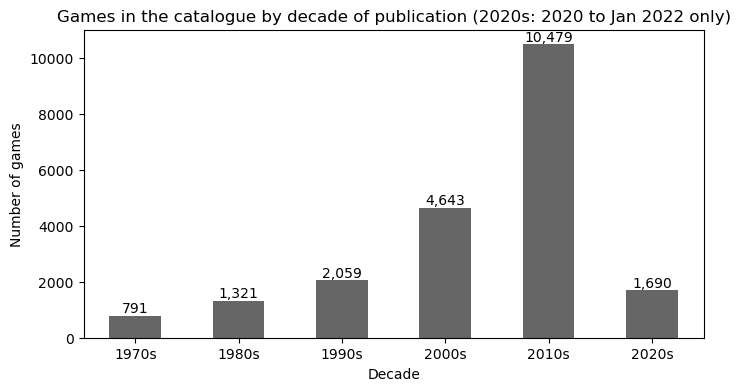

In [5]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Games per decade, with the count on each bar.
ax = counts.plot(kind="bar", color="0.4", figsize=(8, 4), rot=0)
ax.set_title("Games in the catalogue by decade of publication (2020s: 2020 to Jan 2022 only)")
ax.set_xlabel("Decade")
ax.set_ylabel("Number of games")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
save("02_games_per_decade.png")

791 games from the 1970s, 1,321 from the 1980s, 2,059 from the 1990s, 4,643 from the 2000s, 10,479 from the 2010s, and 1,690 from the partial 2020s. Every comparison below is read against these counts.

## 3. Play time

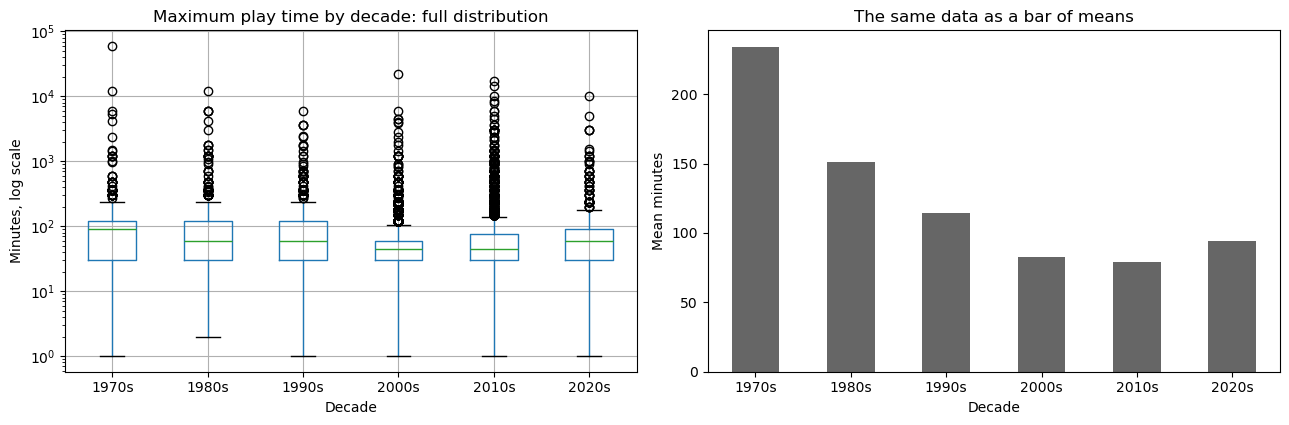

In [6]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Maximum play time by decade: the full distribution on a log scale, next to the same data as a bar of means.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dec.boxplot(column="maxplaytime", by="decade", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Maximum play time by decade: full distribution")
axes[0].set_xlabel("Decade")
axes[0].set_ylabel("Minutes, log scale")
dec.groupby("decade")["maxplaytime"].mean().plot(kind="bar", ax=axes[1], color="0.4", rot=0)
axes[1].set_title("The same data as a bar of means")
axes[1].set_xlabel("Decade")
axes[1].set_ylabel("Mean minutes")
plt.suptitle("")
plt.tight_layout()
save("02_playtime_by_decade.png")

In [7]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# The numbers behind both panels.
dec.groupby("decade")["maxplaytime"].agg(["median", "mean", "count"]).round(1)

,median,mean,count
decade,,,
1970s,90.0,234.3,774
1980s,60.0,151.4,1287
1990s,60.0,114.5,1989
2000s,45.0,82.3,4497
2010s,45.0,79.4,10065
2020s,60.0,94.1,1642


Median maximum play time: 90 minutes in the 1970s, 60 in the 1980s and 1990s, 45 in the 2000s and 2010s, 60 in the 2020s. The means run two to three times higher (234 minutes in the 1970s, 79 in the 2010s) because several hundred games last over 1,000 minutes, so the bar of means shows a much steeper fall than the medians do. The boxes also show that within every decade the middle half of games spans roughly 30 to 120 minutes.

## 4. Player-count range

,Solo play possible,Two players only,Five or more players
decade,,,
1970s,12.6,43.5,23.3
1980s,12.0,29.8,39.2
1990s,9.6,24.6,47.4
2000s,7.6,19.0,48.9
2010s,19.5,11.9,46.6
2020s,44.9,9.5,40.6


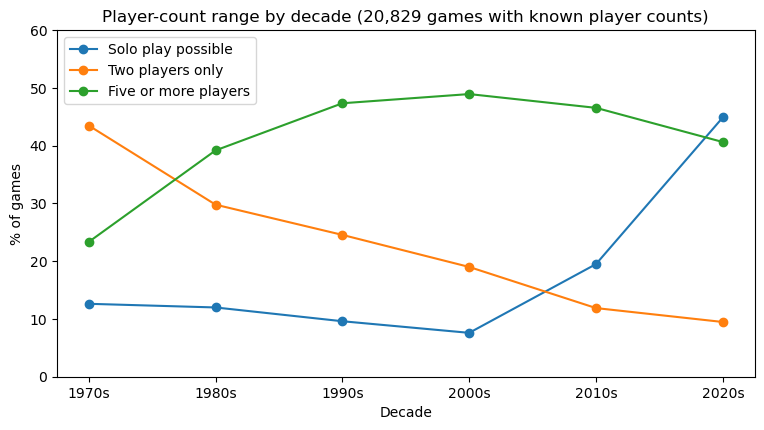

In [8]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Share of games, by decade, that can be played solo, that are two-player only, and that take five or more players.
pc = dec.dropna(subset=["minplayers", "maxplayers"]).copy()
pc["Solo play possible"] = pc["minplayers"] == 1
pc["Two players only"] = (pc["minplayers"] == 2) & (pc["maxplayers"] == 2)
pc["Five or more players"] = pc["maxplayers"] >= 5
shares = pc.groupby("decade")[["Solo play possible", "Two players only", "Five or more players"]].mean() * 100
ax = shares.plot(marker="o", figsize=(9, 4.5))
ax.set_title(f"Player-count range by decade ({len(pc):,} games with known player counts)")
ax.set_xlabel("Decade")
ax.set_ylabel("% of games")
ax.set_ylim(0, 60)
ax.legend(title=None)
save("02_player_counts_by_decade.png")
shares.round(1)

Solo play possible: 12.6% of 1970s games, 7.6% of 2000s games, 19.5% of 2010s games, 44.9% of 2020s games. Two players only: 43.5% in the 1970s falling to 9.5% in the 2020s. Five or more players: 23.3% in the 1970s, then 39% to 49% in every decade since. The median maximum player count is 4 in every decade from the 1980s on.

## 5. Minimum age

,median age,Age 12 or older,Age 8 or younger,games
decade,,,,
1970s,12.0,53.9,28.5,744
1980s,12.0,51.0,28.9,1260
1990s,10.0,47.0,28.1,1941
2000s,10.0,35.5,38.7,4253
2010s,10.0,43.3,35.6,9957
2020s,10.0,48.8,28.0,1613


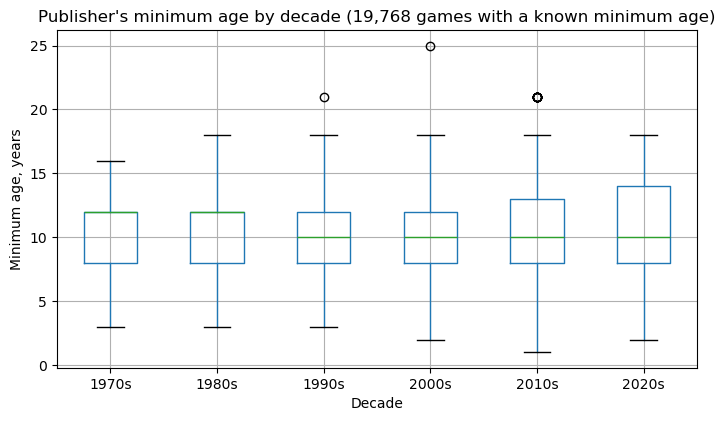

In [9]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Publisher's minimum age by decade, full distribution.
ma = dec.dropna(subset=["minage"]).copy()
ax = ma.boxplot(column="minage", by="decade", figsize=(8, 4.5))
ax.set_title(f"Publisher's minimum age by decade ({len(ma):,} games with a known minimum age)")
ax.set_xlabel("Decade")
ax.set_ylabel("Minimum age, years")
plt.suptitle("")
save("02_min_age_by_decade.png")
ma["Age 12 or older"] = ma["minage"] >= 12
ma["Age 8 or younger"] = ma["minage"] <= 8
pd.concat([
    ma.groupby("decade")["minage"].median().rename("median age"),
    (ma.groupby("decade")[["Age 12 or older", "Age 8 or younger"]].mean() * 100).round(1),
    ma.groupby("decade")["minage"].count().rename("games"),
], axis=1)

Median minimum age: 12 in the 1970s and 1980s, 10 in every decade since. The share of games rated for age 12 or older is 53.9% in the 1970s, falls to 35.5% in the 2000s, and is 48.8% in the 2020s. The share rated for age 8 or younger peaks at 38.7% in the 2000s.

## 6. Number of listed mechanics per game

,median,mean,count
decade,,,
1970s,3.0,3.64,735
1980s,2.0,3.20,1230
1990s,2.0,2.44,1817
2000s,2.0,2.62,4149
2010s,3.0,3.27,9906
2020s,4.0,4.33,1651


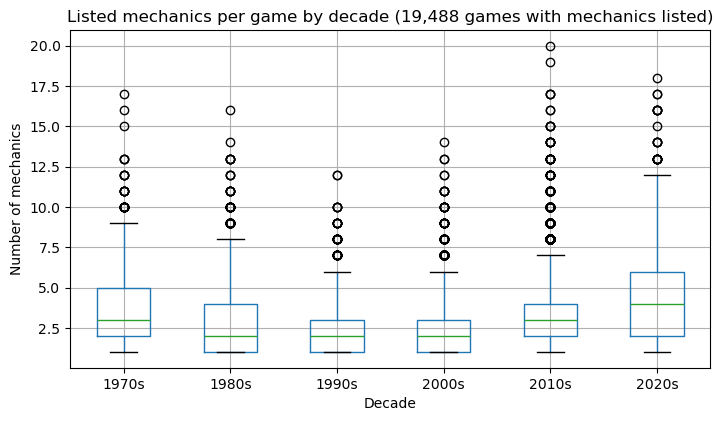

In [10]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Mechanics listed per game, by decade, for games with at least one mechanic listed.
mg = dec[dec["boardgamemechanic"].notna()].copy()
ax = mg.boxplot(column="n_mechanics", by="decade", figsize=(8, 4.5))
ax.set_title(f"Listed mechanics per game by decade ({len(mg):,} games with mechanics listed)")
ax.set_xlabel("Decade")
ax.set_ylabel("Number of mechanics")
plt.suptitle("")
save("02_mechanics_per_game_by_decade.png")
mg.groupby("decade")["n_mechanics"].agg(["median", "mean", "count"]).round(2)

Median mechanics listed per game: 3 in the 1970s, 2 in the 1980s through 2000s, 3 in the 2010s, 4 in the 2020s. The mean follows the same path, from 3.64 to 2.44 and back up to 4.33.

## 7. Which mechanics games use

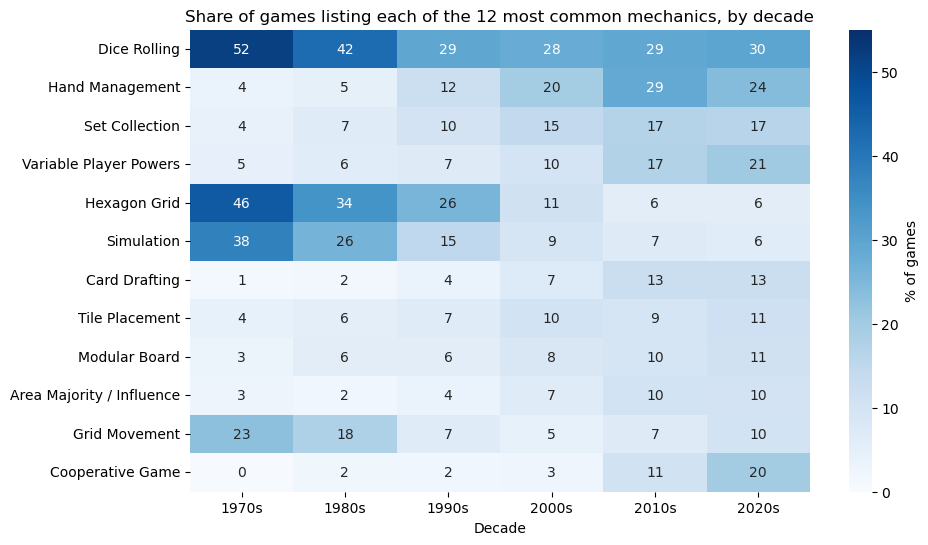

In [11]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Share of games listing each of the 12 most common mechanics, by decade.
mech = mg["boardgamemechanic"].str.get_dummies(sep="|")
top_mech = mech.mean().sort_values(ascending=False).head(12).index
mech_by_decade = pd.concat([mg["decade"], mech[top_mech]], axis=1).groupby("decade").mean() * 100
plt.figure(figsize=(10, 6))
sns.heatmap(mech_by_decade.T, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=55, cbar_kws={"label": "% of games"})
plt.title("Share of games listing each of the 12 most common mechanics, by decade")
plt.xlabel("Decade")
plt.ylabel("")
save("02_mechanics_by_decade.png")

Hexagon Grid appears in 46% of 1970s games and 6% of 2010s and 2020s games; Simulation goes from 38% to 6%; Dice Rolling from 52% to 29%. In the other direction, Hand Management goes from 4% to 29% (2010s), Variable Player Powers from 5% to 21%, Card Drafting from 1% to 13%, and Cooperative Game from 0.4% to 20% (2020s).

## 8. Which categories games belong to

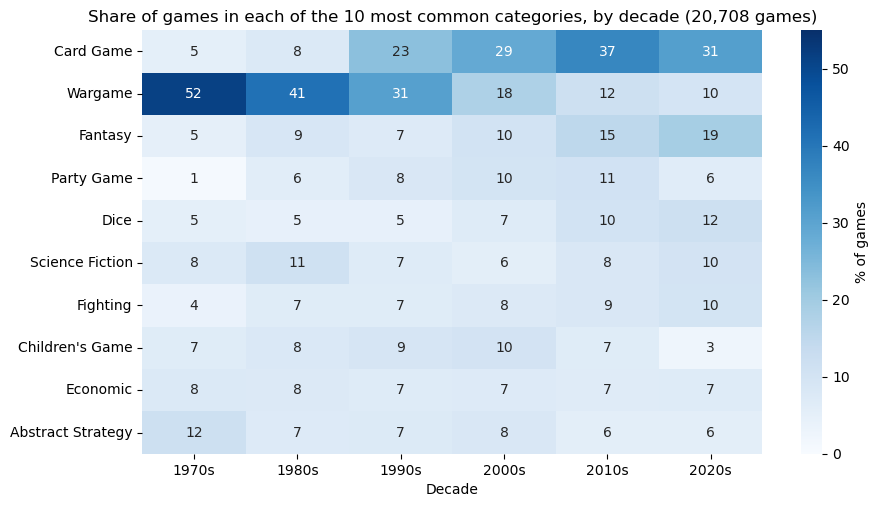

In [12]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-13; reviewed and edited by Sahil Dalal.
# Share of games in each of the 10 most common categories, by decade.
cg = dec[dec["boardgamecategory"].notna()].copy()
cat = cg["boardgamecategory"].str.get_dummies(sep="|")
top_cat = cat.mean().sort_values(ascending=False).head(10).index
cat_by_decade = pd.concat([cg["decade"], cat[top_cat]], axis=1).groupby("decade").mean() * 100
plt.figure(figsize=(10, 5.5))
sns.heatmap(cat_by_decade.T, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=55, cbar_kws={"label": "% of games"})
plt.title(f"Share of games in each of the 10 most common categories, by decade ({len(cg):,} games)")
plt.xlabel("Decade")
plt.ylabel("")
save("02_categories_by_decade.png")

Wargame covers 51.5% of 1970s games and 9.8% of 2020s games. Card Game goes from 5.3% to 36.7% (2010s). Fantasy rises from 4.9% to 19.2%. Children's Game peaks at 10.2% in the 2000s and is 2.5% in the 2020s. Economic and Abstract Strategy stay within a few points of 7% throughout.

## 9. Notes on reading these charts

- The catalogue is a January 2022 snapshot of games with at least 30 user ratings. Older decades therefore contain the games still being rated in 2022, not every game published then.
- The 2020s column covers 2020 and 2021 plus a few early-2022 entries, 1,690 games against 10,479 for the 2010s.
- Mechanic and category shares are shares of games that list at least one mechanic (19,488 games) or category (20,708 games), and a game can be in several.
- Figures are saved to `figures/` with the prefix `02_`.